# Section II: Project Notes

### Model building and interpretation.

a. Build various models (You can choose to build models for either or all of descriptive, predictive or prescriptive purposes)

b. Test your predictive model against the test set using various appropriate performance metrics	 

c.Interpretation of the model(s)	 
 	 
### Model Tuning and business implication

a.Ensemble modelling, wherever applicable	 

b. Any other model tuning measures(if applicable)

c. Interpretation of the most optimum model and its implication on the business	

## Business Problem

In any business, acquiring and retaining customers are two most critical activities that have a direct impact on business success. While acquiring new customers is critical to growth, it is a cost intensive process. By comparison, retaining an existing customer costs 80%-85% less.

Another important metric that should push businesses to work more intently on retaining customers is the propensity to buy. An exisiting customer is 3-12 times more likely to buy compared to a new customer.

With that said, the ability of a business to forecast likelyhood of a customer leaving can greatly help in planning timely and relevant intervention to prevent the churn from happening.

https://www.outboundengine.com/blog/customer-retention-marketing-vs-customer-acquisition-marketing/

In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df1=pd.read_excel('ECom_imputed.xlsx')

In [3]:
def clean_dataset(ds):
    ds.drop('CustomerID', axis=1, inplace=True)
    ds['PreferredLoginDevice'].replace('Mobile Phone','Phone', inplace=True)
    ds['PreferredPaymentMode'].replace('CC','Credit Card', inplace=True)
    ds['PreferredPaymentMode'].replace('Cash on Delivery','COD', inplace=True)
    ds['PreferredPaymentMode'].replace('E wallet','UPI', inplace=True)
    ds['PreferedOrderCat'].replace('Mobile','Mobile Phone', inplace=True)
    
    ds['HourSpendOnApp'] = ds['HourSpendOnApp'].astype('object')
    ds['Churn'] = ds['Churn'].astype('object')
    ds['CityTier'] = ds['CityTier'].astype('object')
    ds['SatisfactionScore'] = ds['SatisfactionScore'].astype('object')
    ds['Complain'] = ds['Complain'].astype('object')
    
    return ds    

In [4]:
df1=clean_dataset(df1)

In [5]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Churn                        5630 non-null   object 
 1   Tenure                       5630 non-null   int64  
 2   PreferredLoginDevice         5630 non-null   object 
 3   CityTier                     5630 non-null   object 
 4   WarehouseToHome              5630 non-null   int64  
 5   PreferredPaymentMode         5630 non-null   object 
 6   Gender                       5630 non-null   object 
 7   HourSpendOnApp               5630 non-null   object 
 8   NumberOfDeviceRegistered     5630 non-null   int64  
 9   PreferedOrderCat             5630 non-null   object 
 10  SatisfactionScore            5630 non-null   object 
 11  MaritalStatus                5630 non-null   object 
 12  NumberOfAddress              5630 non-null   int64  
 13  Complain          

In [6]:
#treat outliers
def treat_outlier(col):
    sorted(col)
    Q1,Q3=np.percentile(col,[25,75])
    IQR=Q3-Q1
    lower_range= Q1-(1.5 * IQR)
    upper_range= Q3+(1.5 * IQR)
    return lower_range, upper_range

In [7]:
for feature in df1.select_dtypes(include='int64').columns: 
    lr,ur=treat_outlier(df1[feature])
    df1[feature]=np.where(df1[feature]>ur,ur,df1[feature])
    df1[feature]=np.where(df1[feature]<lr,lr,df1[feature])

In [8]:
lr,ur=treat_outlier(df1['CashbackAmount'])
df1['CashbackAmount']=np.where(df1['CashbackAmount']>ur,ur,df1['CashbackAmount'])

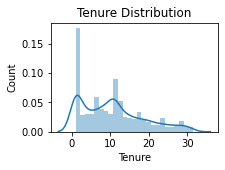

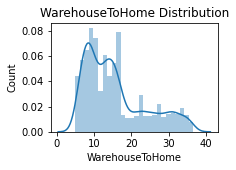

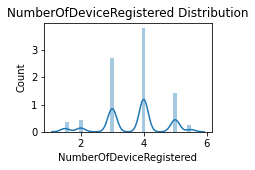

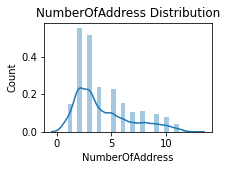

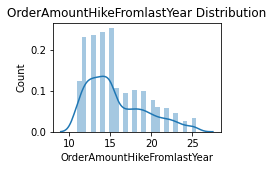

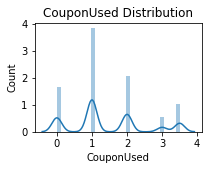

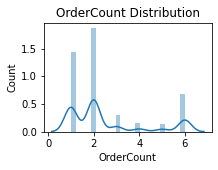

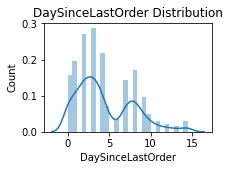

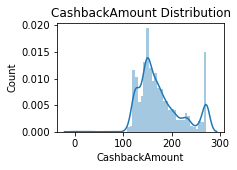

In [9]:
for col in df1.select_dtypes(exclude='object').columns:
    #print(df[col].value_counts(), '\n')
    plt.figure(figsize = (3,2))
    sns.distplot(df1[col])
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.title(col+' Distribution')

In [10]:
from sklearn.preprocessing import RobustScaler
RS = RobustScaler()

In [11]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
le = LabelEncoder()

In [12]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Churn                        5630 non-null   object 
 1   Tenure                       5630 non-null   float64
 2   PreferredLoginDevice         5630 non-null   object 
 3   CityTier                     5630 non-null   object 
 4   WarehouseToHome              5630 non-null   float64
 5   PreferredPaymentMode         5630 non-null   object 
 6   Gender                       5630 non-null   object 
 7   HourSpendOnApp               5630 non-null   object 
 8   NumberOfDeviceRegistered     5630 non-null   float64
 9   PreferedOrderCat             5630 non-null   object 
 10  SatisfactionScore            5630 non-null   object 
 11  MaritalStatus                5630 non-null   object 
 12  NumberOfAddress              5630 non-null   float64
 13  Complain          

In [13]:
for col in df1.select_dtypes(include='object').columns:
    df1[col] = le.fit_transform(df1[col])

In [14]:
df1.head()

,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,1,4.0,1,2,6.0,2,0,2,3.0,2,1,2,9.0,1,11.0,1.0,1.0,5.0,159.93
1,1,1.0,1,0,8.0,3,1,2,4.0,3,2,2,7.0,1,15.0,0.0,1.0,0.0,120.90
2,1,1.0,1,0,30.0,2,1,1,4.0,3,2,2,6.0,1,14.0,0.0,1.0,3.0,120.28
3,1,1.0,1,2,15.0,2,1,1,4.0,2,4,2,8.0,0,23.0,0.0,1.0,3.0,134.07
4,1,1.0,1,0,12.0,1,1,2,3.0,3,4,2,3.0,0,11.0,1.0,1.0,3.0,129.60


In [15]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Churn                        5630 non-null   int32  
 1   Tenure                       5630 non-null   float64
 2   PreferredLoginDevice         5630 non-null   int32  
 3   CityTier                     5630 non-null   int32  
 4   WarehouseToHome              5630 non-null   float64
 5   PreferredPaymentMode         5630 non-null   int32  
 6   Gender                       5630 non-null   int32  
 7   HourSpendOnApp               5630 non-null   int32  
 8   NumberOfDeviceRegistered     5630 non-null   float64
 9   PreferedOrderCat             5630 non-null   int32  
 10  SatisfactionScore            5630 non-null   int32  
 11  MaritalStatus                5630 non-null   int32  
 12  NumberOfAddress              5630 non-null   float64
 13  Complain          

In [16]:
df1.describe().T

,count,mean,std,min,25%,50%,75%,max
Churn,5630.0,0.168384,0.374240,0.0,0.00,0.00,0.0000,1.00000
Tenure,5630.0,10.576377,8.028879,1.0,4.00,10.00,15.0000,31.50000
PreferredLoginDevice,5630.0,0.709769,0.453909,0.0,0.00,1.00,1.0000,1.00000
CityTier,5630.0,0.654707,0.915389,0.0,0.00,0.00,2.0000,2.00000
WarehouseToHome,5630.0,15.520071,8.094867,5.0,9.00,13.00,20.0000,36.50000
PreferredPaymentMode,5630.0,1.684902,0.873914,0.0,1.00,2.00,2.0000,3.00000
Gender,5630.0,0.601066,0.489723,0.0,0.00,1.00,1.0000,1.00000
HourSpendOnApp,5630.0,1.936234,0.702267,0.0,1.00,2.00,2.0000,4.00000
NumberOfDeviceRegistered,5630.0,3.695471,0.942015,1.5,3.00,4.00,4.0000,5.50000
PreferedOrderCat,5630.0,2.096980,1.098866,0.0,2.00,2.00,3.0000,4.00000


In [17]:
X=df1.drop(['Churn'], axis=1)

In [18]:
df1.Churn.value_counts()

0    4682
1     948
Name: Churn, dtype: int64

In [19]:
y=df1.Churn

In [20]:
X.shape

(5630, 18)

In [21]:
y.shape

(5630,)

In [22]:
#Scale X
X=RS.fit_transform(X)


In [23]:
X.shape

(5630, 18)

In [24]:
#import the required libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn import svm
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
#import xgboost as xgb
from sklearn.metrics import confusion_matrix,classification_report,roc_auc_score,accuracy_score,roc_auc_score,roc_curve
from sklearn import metrics

In [25]:
#Train Test Split
X_train,X_test,y_train,y_test=train_test_split(X, y, test_size = 0.30, stratify=df1['Churn'])

In [26]:
y_test.dtype

dtype('int32')

In [27]:
#function to create comparitive dataframe of model performance
def comparison_report(report,auc,model_name):
    report_data = []
    row = {}
    row['class'] = '1'
    row['precision'] = report['1']['precision']
    row['recall'] = report['1']['recall']
    row['f1_score'] = report['1']['f1-score']
    row['support'] = report['1']['support']
    row['AUC'] = auc
    row['Model_Name'] = model_name
    report_data.append(row)
    dataframe = pd.DataFrame.from_dict(report_data)
    return dataframe


In [28]:
LR = LogisticRegression(class_weight='balanced')
LDA = LinearDiscriminantAnalysis()
KNN = KNeighborsClassifier()
GNB = GaussianNB()
SVM = svm.SVC(class_weight='balanced',probability=True)
DTC = DecisionTreeClassifier(class_weight='balanced',max_depth=11, random_state=10)
RFC = RandomForestClassifier(max_depth=9, n_estimators=20, bootstrap=False, class_weight='balanced', random_state=10)

models_x = [LR,LDA,KNN,GNB,SVM,DTC,RFC]

In [29]:
for model in models_x:
    print("Model Name : ",str(model).split("(",1)[0],'\n\n')

Model Name :  LogisticRegression 


Model Name :  LinearDiscriminantAnalysis 


Model Name :  KNeighborsClassifier 


Model Name :  GaussianNB 


Model Name :  SVC 


Model Name :  DecisionTreeClassifier 


Model Name :  RandomForestClassifier 




Model Name :  LogisticRegression 


Train Score :  0.8134991119005328
Confusion Matrix : Train 
 [[2646  631]
 [ 104  560]] 

              precision    recall  f1-score   support

           0       0.96      0.81      0.88      3277
           1       0.47      0.84      0.60       664

    accuracy                           0.81      3941
   macro avg       0.72      0.83      0.74      3941
weighted avg       0.88      0.81      0.83      3941

Test Score :  0.8075784487862641
Confusion Matrix : Test 
 [[1113  292]
 [  33  251]] 

              precision    recall  f1-score   support

           0       0.97      0.79      0.87      1405
           1       0.46      0.88      0.61       284

    accuracy                           0.81      1689
   macro avg       0.72      0.84      0.74      1689
weighted avg       0.89      0.81      0.83      1689

AUC Train: 0.893
AUC Test: 0.903 



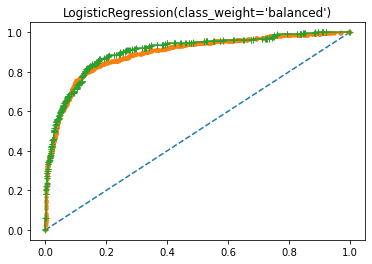

Model Name :  LinearDiscriminantAnalysis 


Train Score :  0.8837858411570667
Confusion Matrix : Train 
 [[3172  105]
 [ 353  311]] 

              precision    recall  f1-score   support

           0       0.90      0.97      0.93      3277
           1       0.75      0.47      0.58       664

    accuracy                           0.88      3941
   macro avg       0.82      0.72      0.75      3941
weighted avg       0.87      0.88      0.87      3941

Test Score :  0.8857312018946122
Confusion Matrix : Test 
 [[1360   45]
 [ 148  136]] 

              precision    recall  f1-score   support

           0       0.90      0.97      0.93      1405
           1       0.75      0.48      0.58       284

    accuracy                           0.89      1689
   macro avg       0.83      0.72      0.76      1689
weighted avg       0.88      0.89      0.88      1689

AUC Train: 0.888
AUC Test: 0.896 



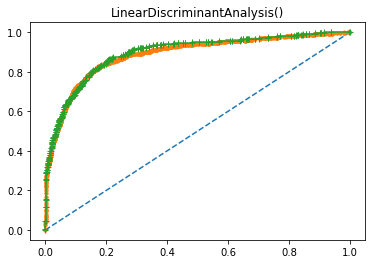

Model Name :  KNeighborsClassifier 


Train Score :  0.9418929205785334
Confusion Matrix : Train 
 [[3242   35]
 [ 194  470]] 

              precision    recall  f1-score   support

           0       0.94      0.99      0.97      3277
           1       0.93      0.71      0.80       664

    accuracy                           0.94      3941
   macro avg       0.94      0.85      0.88      3941
weighted avg       0.94      0.94      0.94      3941

Test Score :  0.9100059206631143
Confusion Matrix : Test 
 [[1375   30]
 [ 122  162]] 

              precision    recall  f1-score   support

           0       0.92      0.98      0.95      1405
           1       0.84      0.57      0.68       284

    accuracy                           0.91      1689
   macro avg       0.88      0.77      0.81      1689
weighted avg       0.91      0.91      0.90      1689

AUC Train: 0.985
AUC Test: 0.943 



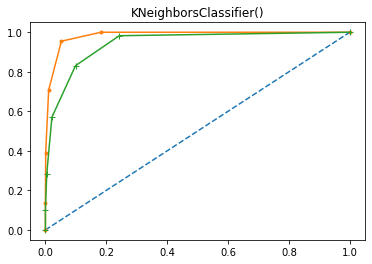

Model Name :  GaussianNB 


Train Score :  0.8779497589444304
Confusion Matrix : Train 
 [[3018  259]
 [ 222  442]] 

              precision    recall  f1-score   support

           0       0.93      0.92      0.93      3277
           1       0.63      0.67      0.65       664

    accuracy                           0.88      3941
   macro avg       0.78      0.79      0.79      3941
weighted avg       0.88      0.88      0.88      3941

Test Score :  0.8727057430432208
Confusion Matrix : Test 
 [[1288  117]
 [  98  186]] 

              precision    recall  f1-score   support

           0       0.93      0.92      0.92      1405
           1       0.61      0.65      0.63       284

    accuracy                           0.87      1689
   macro avg       0.77      0.79      0.78      1689
weighted avg       0.88      0.87      0.87      1689

AUC Train: 0.850
AUC Test: 0.855 



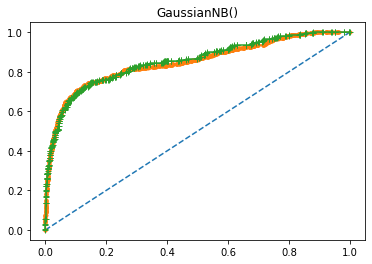

Model Name :  SVC 


Train Score :  0.9248921593504187
Confusion Matrix : Train 
 [[3011  266]
 [  30  634]] 

              precision    recall  f1-score   support

           0       0.99      0.92      0.95      3277
           1       0.70      0.95      0.81       664

    accuracy                           0.92      3941
   macro avg       0.85      0.94      0.88      3941
weighted avg       0.94      0.92      0.93      3941

Test Score :  0.9029011249259917
Confusion Matrix : Test 
 [[1265  140]
 [  24  260]] 

              precision    recall  f1-score   support

           0       0.98      0.90      0.94      1405
           1       0.65      0.92      0.76       284

    accuracy                           0.90      1689
   macro avg       0.82      0.91      0.85      1689
weighted avg       0.93      0.90      0.91      1689

AUC Train: 0.981
AUC Test: 0.965 



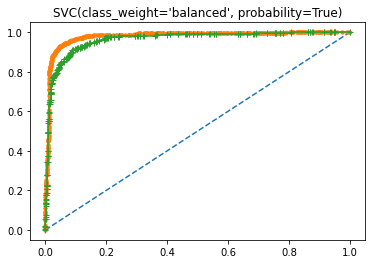

Model Name :  DecisionTreeClassifier 


Train Score :  0.9758944430347628
Confusion Matrix : Train 
 [[3184   93]
 [   2  662]] 

              precision    recall  f1-score   support

           0       1.00      0.97      0.99      3277
           1       0.88      1.00      0.93       664

    accuracy                           0.98      3941
   macro avg       0.94      0.98      0.96      3941
weighted avg       0.98      0.98      0.98      3941

Test Score :  0.9342806394316163
Confusion Matrix : Test 
 [[1322   83]
 [  28  256]] 

              precision    recall  f1-score   support

           0       0.98      0.94      0.96      1405
           1       0.76      0.90      0.82       284

    accuracy                           0.93      1689
   macro avg       0.87      0.92      0.89      1689
weighted avg       0.94      0.93      0.94      1689

AUC Train: 0.998
AUC Test: 0.933 



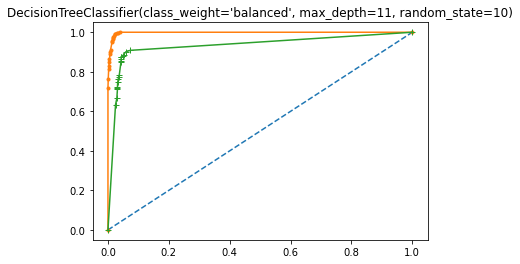

Model Name :  RandomForestClassifier 


Train Score :  0.9822380106571936
Confusion Matrix : Train 
 [[3215   62]
 [   8  656]] 

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      3277
           1       0.91      0.99      0.95       664

    accuracy                           0.98      3941
   macro avg       0.96      0.98      0.97      3941
weighted avg       0.98      0.98      0.98      3941

Test Score :  0.955595026642984
Confusion Matrix : Test 
 [[1349   56]
 [  19  265]] 

              precision    recall  f1-score   support

           0       0.99      0.96      0.97      1405
           1       0.83      0.93      0.88       284

    accuracy                           0.96      1689
   macro avg       0.91      0.95      0.92      1689
weighted avg       0.96      0.96      0.96      1689

AUC Train: 0.999
AUC Test: 0.991 



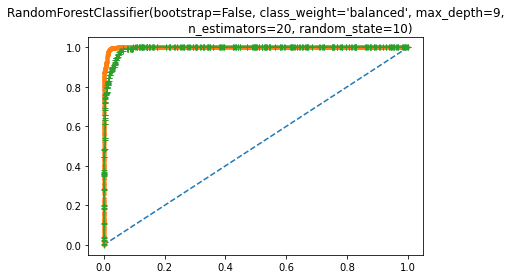

In [30]:
df_result_train=pd.DataFrame()
df_result_test=pd.DataFrame()
for model in models_x:
    
    print("Model Name : ",str(model).split("(",1)[0],'\n\n')
    model.fit(X_train, y_train)
    y_train_p = model.predict(X_train)
    model_score_train = model.score(X_train, y_train)
    print("Train Score : ",model_score_train)
    print("Confusion Matrix : Train \n",metrics.confusion_matrix(y_train, y_train_p),"\n")
    y_predict = model.predict(X_test)
    model_score = model.score(X_test, y_test)
    print(metrics.classification_report(y_train, y_train_p))
    print("Test Score : ",model_score)
    print("Confusion Matrix : Test \n",metrics.confusion_matrix(y_test, y_predict),"\n")
    print(metrics.classification_report(y_test, y_predict))

    #AUC Calculation
    probs = model.predict_proba(X_train)
    proby = model.predict_proba(X_test)
    # keep probabilities for the positive outcome only
    probs = probs[:, 1]
    proby = proby[:, 1]
    # calculate AUC
    auc_train = roc_auc_score(y_train, probs)
    print('AUC Train: %.3f' % auc_train)
    auc_test = roc_auc_score(y_test, proby)
    print('AUC Test: %.3f' % auc_test,'\n')
    
    # calculate roc curve
    fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train, probs)
    fpr_te, tpr_te, thresholds_te = roc_curve(y_test, proby)
    plt.plot([0, 1], [0, 1], linestyle='--')
    # plot the roc curve for the model
    plt.title(model)
    plt.plot(fpr_tr, tpr_tr, marker='.')
    plt.plot(fpr_te, tpr_te, marker='+')
    # show the plot
    plt.show()
    
    
    temp_train=metrics.classification_report(y_train, y_train_p,output_dict=True)
    temp_test=metrics.classification_report(y_test, y_predict,output_dict=True)
    
    df_result_train = pd.concat([df_result_train,comparison_report(temp_train,auc_train,str(model).split("(",1)[0])])
    report_test = metrics.classification_report(y_test, y_predict)
    df_result_test = pd.concat([df_result_test,comparison_report(temp_test,auc_test,str(model).split("(",1)[0])])

In [31]:
df_result_train.set_index('Model_Name')

,class,precision,recall,f1_score,support,AUC
Model_Name,,,,,,
LogisticRegression,1,0.470193,0.843373,0.603774,664,0.893353
LinearDiscriminantAnalysis,1,0.747596,0.468373,0.575926,664,0.888256
KNeighborsClassifier,1,0.930693,0.707831,0.804106,664,0.984942
GaussianNB,1,0.630528,0.665663,0.647619,664,0.850110
SVC,1,0.704444,0.954819,0.810742,664,0.980669
DecisionTreeClassifier,1,0.876821,0.996988,0.933051,664,0.998002
RandomForestClassifier,1,0.913649,0.987952,0.949349,664,0.998539


In [32]:
df_result_test.set_index('Model_Name')

,class,precision,recall,f1_score,support,AUC
Model_Name,,,,,,
LogisticRegression,1,0.462247,0.883803,0.607013,284,0.903276
LinearDiscriminantAnalysis,1,0.751381,0.478873,0.584946,284,0.895907
KNeighborsClassifier,1,0.843750,0.570423,0.680672,284,0.943444
GaussianNB,1,0.613861,0.654930,0.633731,284,0.855366
SVC,1,0.650000,0.915493,0.760234,284,0.964721
DecisionTreeClassifier,1,0.755162,0.901408,0.821830,284,0.932772
RandomForestClassifier,1,0.825545,0.933099,0.876033,284,0.991419


In [33]:
from sklearn import tree

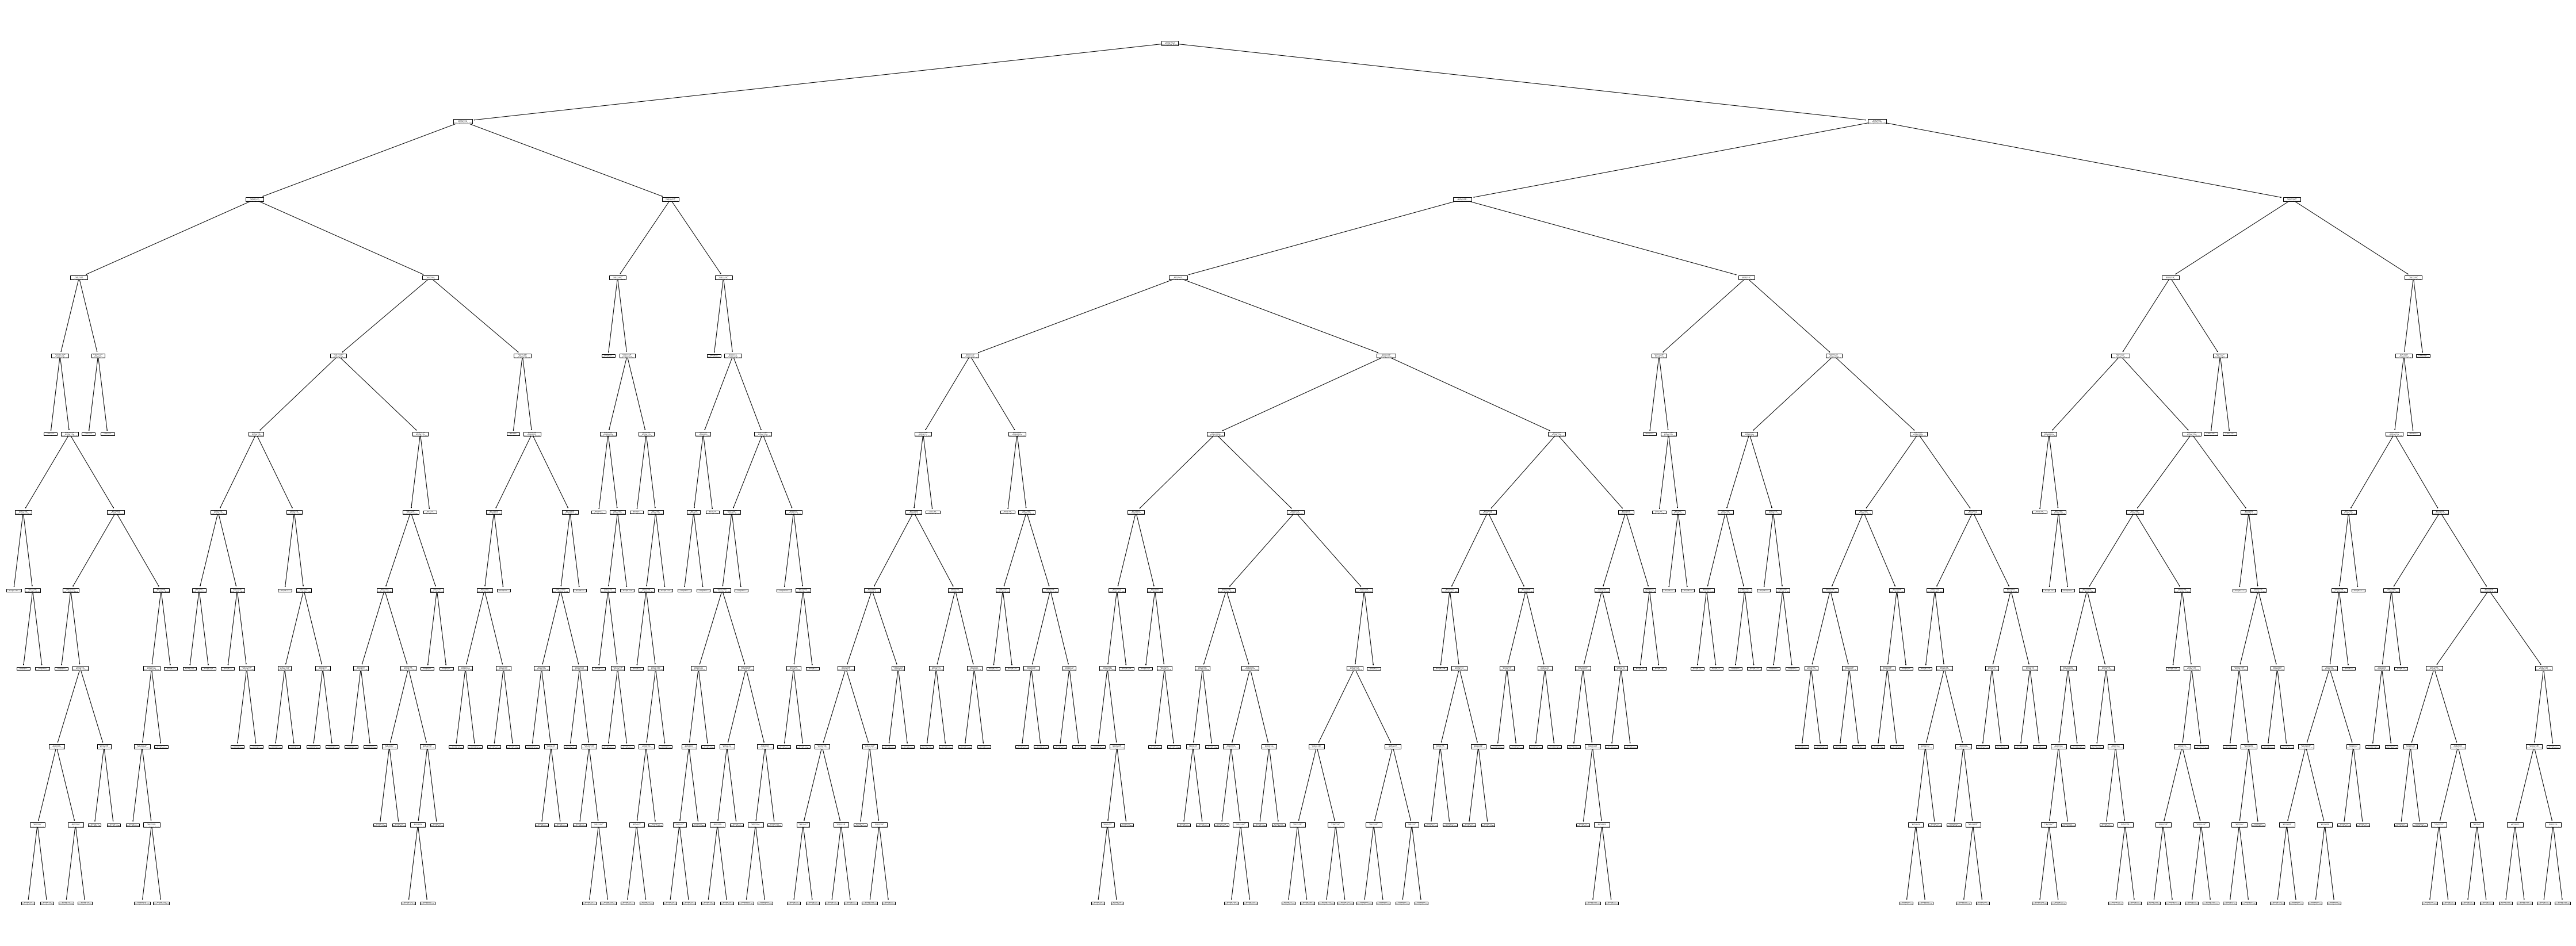

In [34]:
plt.figure(figsize = (80,30))
tree.plot_tree(DTC, max_depth=11);

### Model Tuning

In [35]:
from sklearn.model_selection import GridSearchCV

In [36]:
rfcl = RandomForestClassifier(max_depth=7, bootstrap=False, class_weight='balanced', random_state=10)

In [37]:
models1 = {    
    'LR' : (LogisticRegression()),
    'LDA' : (LinearDiscriminantAnalysis()),
    'KNN' : (KNeighborsClassifier()),
    'GNB' : (GaussianNB()),
    'SVM' : (svm.SVC()),
    'DTC' : (DecisionTreeClassifier(random_state=10)),
    'RFC' : (RandomForestClassifier(random_state=10)),
    'BAG' : (BaggingClassifier(base_estimator=rfcl)),
    'ADA' : (AdaBoostClassifier(base_estimator=rfcl)),
    'GBC' : (GradientBoostingClassifier())
}

params1 = {
    'LR' : { 'penalty': ['l1', 'l2', 'elasticnet', 'none'], 'class_weight' : ['balanced', None],'solver' : ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga'] , 'max_iter' : [100, 500, 1000]},
    'LDA': { 'solver' : ['svd', 'lsqr', 'eigen'], 'shrinkage' : ['auto', None]},
    'KNN': { 'n_neighbors' : [3,5,7], 'weights' : ['uniform','distance']},
    'GNB': { },
    'SVM': [
        {'kernel': ['linear'], 'C': [1, 10], 'max_iter' : [-1, 10, 100], 'class_weight' : ['balanced', None]},
        {'kernel': ['rbf'], 'C': [1, 10], 'max_iter' : [-1, 10, 100], 'class_weight' : ['balanced', None], 'gamma': [0.001, 0.0001]},
        {'class_weight' : ['balanced']}
    ],
    'DTC': { 'criterion':['gini','entropy'],'max_features' : ["auto", "sqrt", "log2"], 'max_depth' : [9,10,11,12], 'min_samples_split':[2,3,4]},
    'RFC': { 'n_estimators' : [120,150,180],'criterion':['gini','entropy'],'max_features' : ["auto", "sqrt", "log2"], 'max_depth' : [9,10,11,12], 'min_samples_split':[2,3,4], 'class_weight' : ['balanced', 'balanced_subsample']},
    'BAG': { 'n_estimators' : [200,500,600], 'max_features' : [7,10,15,18]},
    'ADA':  { 'n_estimators': [10,100,500], 'learning_rate': [0.8, 1.0] },
    'GBC': { 'loss' : ['deviance', 'exponential'], 'n_estimators': [10,100,500], 'learning_rate': [0.8, 1.0], 'max_features' : ['auto',10,15,18]},
    
}

In [38]:
class EstimatorSelectionHelper:

    def __init__(self, models, params):
        if not set(models.keys()).issubset(set(params.keys())):
            missing_params = list(set(models.keys()) - set(params.keys()))
            raise ValueError("Some estimators are missing parameters: %s" % missing_params)
        self.models = models
        self.params = params
        self.keys = models.keys()
        self.grid_searches = {}

    def fit(self, X, y, cv=5, n_jobs=-1, verbose=1, scoring=None, refit=True):
        for key in self.keys:
            print("Running GridSearchCV for %s." % key)
            model = self.models[key]
            params = self.params[key]
            gs = GridSearchCV(model, params, cv=cv, n_jobs=n_jobs,
                              verbose=verbose, scoring=scoring, refit=refit,
                              return_train_score=True)
            gs.fit(X,y)
            print(gs.best_params_)
            print(metrics.recall_score(y,gs.predict(X),pos_label=1))
            self.grid_searches[key] = gs    

    def score_summary(self, sort_by='mean_score'):
        def row(key, scores, params):
            d = {
                 'estimator': key,
                 'min_score': min(scores),
                 'max_score': max(scores),
                 'mean_score': np.mean(scores),
                 'std_score': np.std(scores),
            }
            return pd.Series({**params,**d})

        rows = []
        for k in self.grid_searches:
            print(k)
            params = self.grid_searches[k].cv_results_['params']
            scores = []
            best_par = []
            for i in range(self.grid_searches[k].cv):
                key = "split{}_test_score".format(i)
                r = self.grid_searches[k].cv_results_[key]
                #bp= self.grid_searches[k].best_params_[key]
                scores.append(r.reshape(len(params),1))
                #best_par.append(bp.reshape(len(params),1))

            all_scores = np.hstack(scores)
            for p, s in zip(params,all_scores):
                rows.append((row(k, s, p)))

        df = pd.concat(rows, axis=1).T.sort_values([sort_by], ascending=False)

        columns = ['estimator', 'min_score', 'mean_score', 'max_score', 'std_score']
        columns = columns + [c for c in df.columns if c not in columns]

        return df[columns]

In [39]:
helper1 = EstimatorSelectionHelper(models1, params1)
helper1.fit(X_train, y_train, scoring='recall', n_jobs=-1)

Running GridSearchCV for LR.
Fitting 5 folds for each of 120 candidates, totalling 600 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    2.4s
[Parallel(n_jobs=-1)]: Done 436 tasks      | elapsed:    3.2s
[Parallel(n_jobs=-1)]: Done 569 out of 600 | elapsed:    3.4s remaining:    0.1s
[Parallel(n_jobs=-1)]: Done 600 out of 600 | elapsed:    3.5s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.


{'class_weight': 'balanced', 'max_iter': 100, 'penalty': 'l1', 'solver': 'liblinear'}
0.8433734939759037
Running GridSearchCV for LDA.
Fitting 5 folds for each of 6 candidates, totalling 30 fits
{'shrinkage': None, 'solver': 'svd'}
0.4683734939759036
Running GridSearchCV for KNN.
Fitting 5 folds for each of 6 candidates, totalling 30 fits


[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:    1.1s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:    1.1s finished


{'n_neighbors': 3, 'weights': 'distance'}
1.0
Running GridSearchCV for GNB.
Fitting 5 folds for each of 1 candidates, totalling 5 fits
{}
0.6656626506024096
Running GridSearchCV for SVM.
Fitting 5 folds for each of 37 candidates, totalling 185 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 154 out of 185 | elapsed:    2.5s remaining:    0.4s
[Parallel(n_jobs=-1)]: Done 185 out of 185 | elapsed:    3.9s finished
C:\ProgramData\Anaconda3\lib\site-packages\sklearn\svm\_base.py:246: ConvergenceWarning: Solver terminated early (max_iter=10).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn('Solver terminated early (max_iter=%i).'
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.0s


... (7 outputs left out)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:    7.5s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:    7.5s finished


{'learning_rate': 1.0, 'n_estimators': 500}
1.0
Running GridSearchCV for GBC.
Fitting 5 folds for each of 48 candidates, totalling 240 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.4s
[Parallel(n_jobs=-1)]: Done 240 out of 240 | elapsed:   15.3s finished


{'learning_rate': 0.8, 'loss': 'deviance', 'max_features': 15, 'n_estimators': 100}
1.0


In [40]:
helper1.score_summary(sort_by='max_score').to_excel("out.xls")

LR
LDA
KNN
GNB
SVM
DTC
RFC
BAG
ADA
GBC


In [41]:
models2 = {    
    'LR' : (LogisticRegression(class_weight= None, max_iter= 100, penalty='none', solver= 'newton-cg')),
    'LDA' : (LinearDiscriminantAnalysis(shrinkage= 'auto', solver= 'lsqr')),
    'KNN' : (KNeighborsClassifier(n_neighbors= 3, weights= 'uniform', p=1)),
    'SVM' : (svm.SVC(C= 10, class_weight= None, kernel= 'rbf', max_iter= 100,probability=True, gamma=0.0001 )),
    'DTC' : (DecisionTreeClassifier(random_state=10,criterion= 'entropy', max_depth= 12, max_features= 'auto', min_samples_split= 2)),
    'RFC' : (RandomForestClassifier(random_state=10, class_weight= 'balanced_subsample', criterion= 'gini', max_depth= 10, max_features= 'sqrt', min_samples_split= 2, n_estimators= 180 )),
    'BAG' : (BaggingClassifier(base_estimator=rfcl,max_features= 10, n_estimators= 500)),
    'ADA' : (AdaBoostClassifier(base_estimator=rfcl, learning_rate= 0.8, n_estimators= 500)),
    'GBC' : (GradientBoostingClassifier(learning_rate= 0.8, loss= 'exponential', max_features= 15, n_estimators= 100))
}

In [42]:
Best_params = {
    'LR' : {'class_weight': None, 'max_iter': 100, 'penalty': 'l2', 'solver': 'liblinear'},
    'LDA': {'shrinkage': 'auto', 'solver': 'lsqr'},
    'KNN': {'n_neighbors': 3, 'weights': 'distance'},
    'GNB': { },
    'SVM': {'C': 10, 'class_weight': None, 'kernel': 'linear', 'max_iter': -1},
    'BAG': {'max_features': 18, 'n_estimators': 100},
    'ADA': {'learning_rate': 0.8, 'n_estimators': 500},
    'GBC': {'learning_rate': 0.8, 'loss': 'deviance', 'max_features': 10, 'n_estimators': 100}
}

In [43]:
models_tuned=list(models2.keys())

In [44]:
models_tuned

['LR', 'LDA', 'KNN', 'SVM', 'DTC', 'RFC', 'BAG', 'ADA', 'GBC']

Model Name :  LR 


Train Score :  0.8957117482872368
Confusion Matrix : Train 
 [[3174  103]
 [ 308  356]] 

              precision    recall  f1-score   support

           0       0.91      0.97      0.94      3277
           1       0.78      0.54      0.63       664

    accuracy                           0.90      3941
   macro avg       0.84      0.75      0.79      3941
weighted avg       0.89      0.90      0.89      3941

Test Score :  0.8916518650088809
Confusion Matrix : Test 
 [[1353   52]
 [ 131  153]] 

              precision    recall  f1-score   support

           0       0.91      0.96      0.94      1405
           1       0.75      0.54      0.63       284

    accuracy                           0.89      1689
   macro avg       0.83      0.75      0.78      1689
weighted avg       0.88      0.89      0.88      1689

AUC Train: 0.893
AUC Test: 0.905 



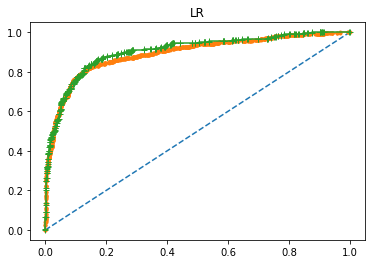

Model Name :  LDA 


Train Score :  0.8842933265668612
Confusion Matrix : Train 
 [[3176  101]
 [ 355  309]] 

              precision    recall  f1-score   support

           0       0.90      0.97      0.93      3277
           1       0.75      0.47      0.58       664

    accuracy                           0.88      3941
   macro avg       0.83      0.72      0.75      3941
weighted avg       0.87      0.88      0.87      3941

Test Score :  0.8863232682060391
Confusion Matrix : Test 
 [[1361   44]
 [ 148  136]] 

              precision    recall  f1-score   support

           0       0.90      0.97      0.93      1405
           1       0.76      0.48      0.59       284

    accuracy                           0.89      1689
   macro avg       0.83      0.72      0.76      1689
weighted avg       0.88      0.89      0.88      1689

AUC Train: 0.888
AUC Test: 0.896 



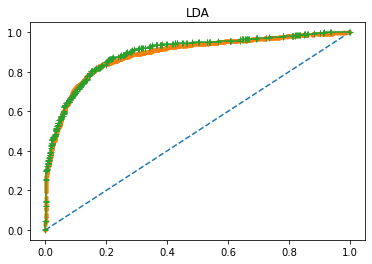

Model Name :  KNN 


Train Score :  0.9832529814767825
Confusion Matrix : Train 
 [[3257   20]
 [  46  618]] 

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3277
           1       0.97      0.93      0.95       664

    accuracy                           0.98      3941
   macro avg       0.98      0.96      0.97      3941
weighted avg       0.98      0.98      0.98      3941

Test Score :  0.9194789816459443
Confusion Matrix : Test 
 [[1354   51]
 [  85  199]] 

              precision    recall  f1-score   support

           0       0.94      0.96      0.95      1405
           1       0.80      0.70      0.75       284

    accuracy                           0.92      1689
   macro avg       0.87      0.83      0.85      1689
weighted avg       0.92      0.92      0.92      1689

AUC Train: 0.996
AUC Test: 0.951 



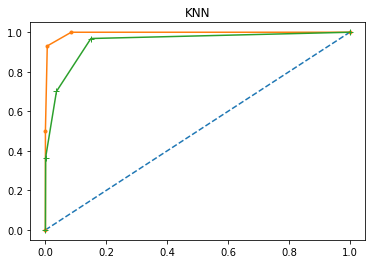

Model Name :  SVM 


Train Score :  0.542755645775184
Confusion Matrix : Train 
 [[1552 1725]
 [  77  587]] 

              precision    recall  f1-score   support

           0       0.95      0.47      0.63      3277
           1       0.25      0.88      0.39       664

    accuracy                           0.54      3941
   macro avg       0.60      0.68      0.51      3941
weighted avg       0.83      0.54      0.59      3941

Test Score :  0.5375962107756068
Confusion Matrix : Test 
 [[650 755]
 [ 26 258]] 

              precision    recall  f1-score   support

           0       0.96      0.46      0.62      1405
           1       0.25      0.91      0.40       284

    accuracy                           0.54      1689
   macro avg       0.61      0.69      0.51      1689
weighted avg       0.84      0.54      0.59      1689

AUC Train: 0.814
AUC Test: 0.837 



C:\ProgramData\Anaconda3\lib\site-packages\sklearn\svm\_base.py:246: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn('Solver terminated early (max_iter=%i).'


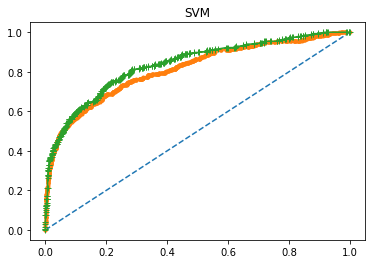

Model Name :  DTC 


Train Score :  0.9766556711494545
Confusion Matrix : Train 
 [[3257   20]
 [  72  592]] 

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      3277
           1       0.97      0.89      0.93       664

    accuracy                           0.98      3941
   macro avg       0.97      0.94      0.96      3941
weighted avg       0.98      0.98      0.98      3941

Test Score :  0.9484902309058615
Confusion Matrix : Test 
 [[1356   49]
 [  38  246]] 

              precision    recall  f1-score   support

           0       0.97      0.97      0.97      1405
           1       0.83      0.87      0.85       284

    accuracy                           0.95      1689
   macro avg       0.90      0.92      0.91      1689
weighted avg       0.95      0.95      0.95      1689

AUC Train: 0.997
AUC Test: 0.948 



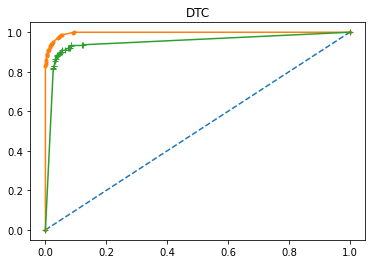

Model Name :  RFC 


Train Score :  0.9918802334432885
Confusion Matrix : Train 
 [[3251   26]
 [   6  658]] 

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      3277
           1       0.96      0.99      0.98       664

    accuracy                           0.99      3941
   macro avg       0.98      0.99      0.99      3941
weighted avg       0.99      0.99      0.99      3941

Test Score :  0.9650680876258141
Confusion Matrix : Test 
 [[1370   35]
 [  24  260]] 

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1405
           1       0.88      0.92      0.90       284

    accuracy                           0.97      1689
   macro avg       0.93      0.95      0.94      1689
weighted avg       0.97      0.97      0.97      1689

AUC Train: 1.000
AUC Test: 0.993 



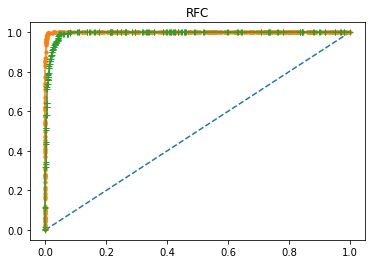

Model Name :  BAG 


Train Score :  0.9474752600862725
Confusion Matrix : Train 
 [[3143  134]
 [  73  591]] 

              precision    recall  f1-score   support

           0       0.98      0.96      0.97      3277
           1       0.82      0.89      0.85       664

    accuracy                           0.95      3941
   macro avg       0.90      0.92      0.91      3941
weighted avg       0.95      0.95      0.95      3941

Test Score :  0.9283599763173476
Confusion Matrix : Test 
 [[1322   83]
 [  38  246]] 

              precision    recall  f1-score   support

           0       0.97      0.94      0.96      1405
           1       0.75      0.87      0.80       284

    accuracy                           0.93      1689
   macro avg       0.86      0.90      0.88      1689
weighted avg       0.93      0.93      0.93      1689

AUC Train: 0.988
AUC Test: 0.977 



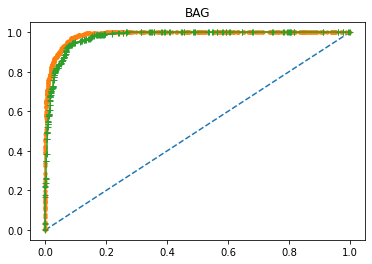

Model Name :  ADA 


Train Score :  0.9944176604922609
Confusion Matrix : Train 
 [[3255   22]
 [   0  664]] 

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      3277
           1       0.97      1.00      0.98       664

    accuracy                           0.99      3941
   macro avg       0.98      1.00      0.99      3941
weighted avg       0.99      0.99      0.99      3941

Test Score :  0.9763173475429248
Confusion Matrix : Test 
 [[1371   34]
 [   6  278]] 

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      1405
           1       0.89      0.98      0.93       284

    accuracy                           0.98      1689
   macro avg       0.94      0.98      0.96      1689
weighted avg       0.98      0.98      0.98      1689

AUC Train: 1.000
AUC Test: 0.996 



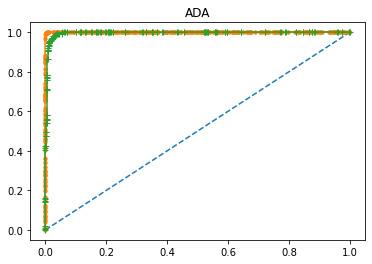

Model Name :  GBC 


Train Score :  0.9974625729510277
Confusion Matrix : Train 
 [[3274    3]
 [   7  657]] 

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3277
           1       1.00      0.99      0.99       664

    accuracy                           1.00      3941
   macro avg       1.00      0.99      1.00      3941
weighted avg       1.00      1.00      1.00      3941

Test Score :  0.9662522202486679
Confusion Matrix : Test 
 [[1375   30]
 [  27  257]] 

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1405
           1       0.90      0.90      0.90       284

    accuracy                           0.97      1689
   macro avg       0.94      0.94      0.94      1689
weighted avg       0.97      0.97      0.97      1689

AUC Train: 1.000
AUC Test: 0.991 



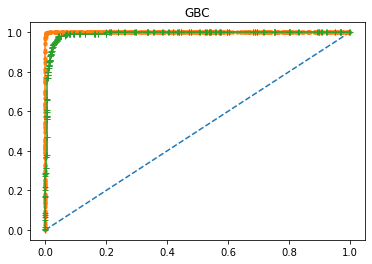

In [45]:
df_result_train_tuned=pd.DataFrame()
df_result_test_tuned=pd.DataFrame()
df_predicted=pd.DataFrame()
for model in models_tuned:
    print("Model Name : ",model,'\n\n')
    models2[model].fit(X_train, y_train)
    y_train_p = models2[model].predict(X_train)
    model_score_train = models2[model].score(X_train, y_train)
    print("Train Score : ",model_score_train)
    print("Confusion Matrix : Train \n",metrics.confusion_matrix(y_train, y_train_p),"\n")
    y_predict = models2[model].predict(X_test)
    model_score = models2[model].score(X_test, y_test)
    print(metrics.classification_report(y_train, y_train_p))
    print("Test Score : ",model_score)
    print("Confusion Matrix : Test \n",metrics.confusion_matrix(y_test, y_predict),"\n")
    print(metrics.classification_report(y_test, y_predict))
    df_predicted[model]=models2[model].predict(X)

#AUC Calculation
    probs = models2[model].predict_proba(X_train)
    proby = models2[model].predict_proba(X_test)
    # keep probabilities for the positive outcome only
    probs = probs[:, 1]
    proby = proby[:, 1]
    # calculate AUC
    auc_train = roc_auc_score(y_train, probs)
    print('AUC Train: %.3f' % auc_train)
    auc_test = roc_auc_score(y_test, proby)
    print('AUC Test: %.3f' % auc_test,'\n')
    
    # calculate roc curve
    fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train, probs)
    fpr_te, tpr_te, thresholds_te = roc_curve(y_test, proby)
    plt.plot([0, 1], [0, 1], linestyle='--')
    # plot the roc curve for the model
    
    plt.title(model)
    plt.plot(fpr_tr, tpr_tr, marker='.')
    plt.plot(fpr_te, tpr_te, marker='+')
    # show the plot
    plt.show()
    
    temp_train=metrics.classification_report(y_train, y_train_p,output_dict=True)
    temp_test=metrics.classification_report(y_test, y_predict,output_dict=True)
    
    df_result_train_tuned = pd.concat([df_result_train_tuned,comparison_report(temp_train,auc_train,model)])
    df_result_test_tuned = pd.concat([df_result_test_tuned,comparison_report(temp_test,auc_test,model)])

In [46]:
df_predicted

,LR,LDA,KNN,SVM,DTC,RFC,BAG,ADA,GBC
0,1,1,1,1,1,1,1,1,1
1,1,1,1,1,1,1,1,1,1
2,1,1,1,1,1,1,1,1,1
3,1,1,1,1,1,1,1,1,1
4,0,0,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...
5625,0,0,0,1,0,0,0,0,0
5626,0,0,0,0,0,0,0,0,0
5627,0,0,0,1,0,0,0,0,0
5628,0,0,0,0,0,0,0,0,0


In [47]:
df_result_train_tuned.set_index('Model_Name', inplace=True)


In [48]:
df_result_train_tuned

,class,precision,recall,f1_score,support,AUC
Model_Name,,,,,,
LR,1,0.775599,0.536145,0.634016,664,0.893434
LDA,1,0.753659,0.465361,0.575419,664,0.888115
KNN,1,0.968652,0.930723,0.949309,664,0.995540
SVM,1,0.253893,0.884036,0.394489,664,0.813810
DTC,1,0.967320,0.891566,0.927900,664,0.996612
RFC,1,0.961988,0.990964,0.976261,664,0.999676
BAG,1,0.815172,0.890060,0.850972,664,0.987605
ADA,1,0.967930,1.000000,0.983704,664,0.999986
GBC,1,0.995455,0.989458,0.992447,664,0.999966


In [49]:
df_result_test_tuned.set_index('Model_Name', inplace=True)

In [50]:
df_result_test_tuned

,class,precision,recall,f1_score,support,AUC
Model_Name,,,,,,
LR,1,0.746341,0.538732,0.625767,284,0.905456
LDA,1,0.755556,0.478873,0.586207,284,0.896083
KNN,1,0.796000,0.700704,0.745318,284,0.950610
SVM,1,0.254689,0.908451,0.397841,284,0.837444
DTC,1,0.833898,0.866197,0.849741,284,0.948327
RFC,1,0.881356,0.915493,0.898100,284,0.993045
BAG,1,0.747720,0.866197,0.802610,284,0.977390
ADA,1,0.891026,0.978873,0.932886,284,0.995990
GBC,1,0.895470,0.904930,0.900175,284,0.991459


In [51]:
df_result_train_tuned.drop('class', axis=1).subtract(df_result_test_tuned.drop('class', axis=1))

,precision,recall,f1_score,support,AUC
Model_Name,,,,,
LR,0.029258,-0.002588,0.008249,380,-0.012022
LDA,-0.001897,-0.013512,-0.010788,380,-0.007968
KNN,0.172652,0.230019,0.203990,380,0.044930
SVM,-0.000796,-0.024415,-0.003352,380,-0.023634
DTC,0.133422,0.025369,0.078159,380,0.048285
RFC,0.080632,0.075471,0.078161,380,0.006631
BAG,0.067452,0.023863,0.048362,380,0.010216
ADA,0.076904,0.021127,0.050818,380,0.003996
GBC,0.099984,0.084528,0.092272,380,0.008507


In [52]:
#Train Test Split
X_train_2p,X_test_2p,y_train_2p,y_test_2p=train_test_split(df_predicted, y, test_size = 0.40, stratify=df1['Churn'])

In [112]:
LR.fit(X_train_2p,y_train_2p)

LogisticRegression(class_weight='balanced')

In [113]:
y_tr_2p_out=LR.predict(X_train_2p)

In [114]:
LR.score(X_train_2p,y_train_2p)

0.9905269390171699

In [115]:
print(metrics.classification_report(y_train_2p,y_tr_2p_out))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2809
           1       0.96      0.99      0.97       569

    accuracy                           0.99      3378
   macro avg       0.98      0.99      0.98      3378
weighted avg       0.99      0.99      0.99      3378



In [116]:
y_te_2p_out=LR.predict(X_test_2p)

In [117]:
print(metrics.classification_report(y_test_2p,y_te_2p_out))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1873
           1       0.94      1.00      0.97       379

    accuracy                           0.99      2252
   macro avg       0.97      0.99      0.98      2252
weighted avg       0.99      0.99      0.99      2252



In [59]:
LR_2p = LogisticRegression(class_weight='balanced')
LDA_2p = LinearDiscriminantAnalysis()
KNN_2p = KNeighborsClassifier()
GNB_2p = GaussianNB()
SVM_2p = svm.SVC(class_weight='balanced',probability=True)
DTC_2p = DecisionTreeClassifier(class_weight='balanced',max_depth=11, random_state=10)
RFC_2p = RandomForestClassifier(max_depth=9, n_estimators=20, bootstrap=False, class_weight='balanced', random_state=10)

models_2p = [LR_2p,LDA_2p,KNN_2p,GNB_2p,SVM_2p,DTC_2p,RFC_2p]

Model Name :  LogisticRegression 


Train Score :  0.9905269390171699
Confusion Matrix : Train 
 [[2783   26]
 [   6  563]] 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2809
           1       0.96      0.99      0.97       569

    accuracy                           0.99      3378
   macro avg       0.98      0.99      0.98      3378
weighted avg       0.99      0.99      0.99      3378

Test Score :  0.988898756660746
Confusion Matrix : Test 
 [[1848   25]
 [   0  379]] 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1873
           1       0.94      1.00      0.97       379

    accuracy                           0.99      2252
   macro avg       0.97      0.99      0.98      2252
weighted avg       0.99      0.99      0.99      2252

AUC Train: 0.996
AUC Test: 0.999 



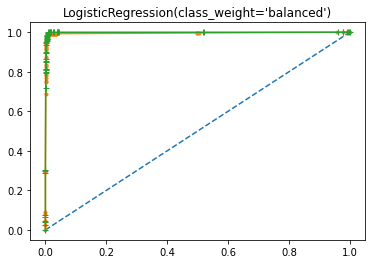

Model Name :  LinearDiscriminantAnalysis 


Train Score :  0.9908229721728834
Confusion Matrix : Train 
 [[2787   22]
 [   9  560]] 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2809
           1       0.96      0.98      0.97       569

    accuracy                           0.99      3378
   macro avg       0.98      0.99      0.98      3378
weighted avg       0.99      0.99      0.99      3378

Test Score :  0.9902309058614565
Confusion Matrix : Test 
 [[1855   18]
 [   4  375]] 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1873
           1       0.95      0.99      0.97       379

    accuracy                           0.99      2252
   macro avg       0.98      0.99      0.98      2252
weighted avg       0.99      0.99      0.99      2252

AUC Train: 0.994
AUC Test: 0.998 



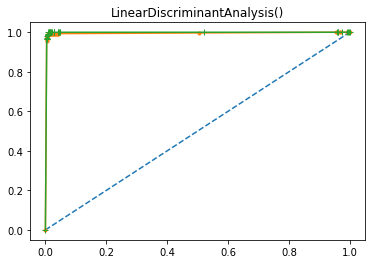

Model Name :  KNeighborsClassifier 


Train Score :  0.9923031379514505
Confusion Matrix : Train 
 [[2794   15]
 [  11  558]] 

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      2809
           1       0.97      0.98      0.98       569

    accuracy                           0.99      3378
   macro avg       0.98      0.99      0.99      3378
weighted avg       0.99      0.99      0.99      3378

Test Score :  0.9911190053285968
Confusion Matrix : Test 
 [[1859   14]
 [   6  373]] 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1873
           1       0.96      0.98      0.97       379

    accuracy                           0.99      2252
   macro avg       0.98      0.99      0.98      2252
weighted avg       0.99      0.99      0.99      2252

AUC Train: 0.996
AUC Test: 0.998 



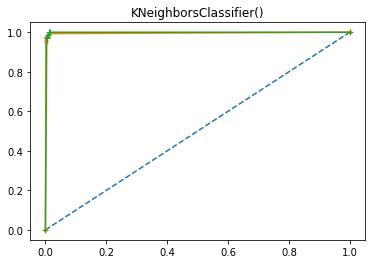

Model Name :  GaussianNB 


Train Score :  0.9869745411486086
Confusion Matrix : Train 
 [[2769   40]
 [   4  565]] 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2809
           1       0.93      0.99      0.96       569

    accuracy                           0.99      3378
   macro avg       0.97      0.99      0.98      3378
weighted avg       0.99      0.99      0.99      3378

Test Score :  0.9844582593250444
Confusion Matrix : Test 
 [[1838   35]
 [   0  379]] 

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      1873
           1       0.92      1.00      0.96       379

    accuracy                           0.98      2252
   macro avg       0.96      0.99      0.97      2252
weighted avg       0.99      0.98      0.98      2252

AUC Train: 0.991
AUC Test: 0.992 



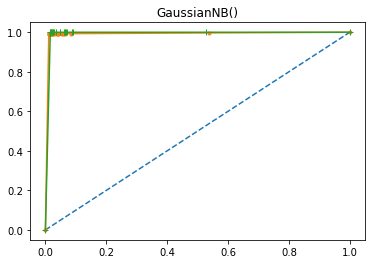

Model Name :  SVC 


Train Score :  0.9914150384843102
Confusion Matrix : Train 
 [[2784   25]
 [   4  565]] 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2809
           1       0.96      0.99      0.97       569

    accuracy                           0.99      3378
   macro avg       0.98      0.99      0.98      3378
weighted avg       0.99      0.99      0.99      3378

Test Score :  0.9897868561278863
Confusion Matrix : Test 
 [[1850   23]
 [   0  379]] 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1873
           1       0.94      1.00      0.97       379

    accuracy                           0.99      2252
   macro avg       0.97      0.99      0.98      2252
weighted avg       0.99      0.99      0.99      2252

AUC Train: 0.996
AUC Test: 0.998 



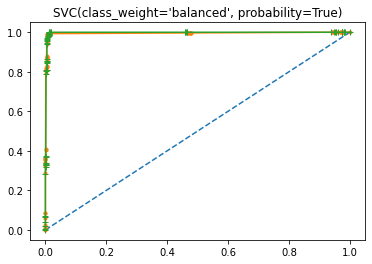

Model Name :  DecisionTreeClassifier 


Train Score :  0.9934872705743043
Confusion Matrix : Train 
 [[2791   18]
 [   4  565]] 

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      2809
           1       0.97      0.99      0.98       569

    accuracy                           0.99      3378
   macro avg       0.98      0.99      0.99      3378
weighted avg       0.99      0.99      0.99      3378

Test Score :  0.9880106571936057
Confusion Matrix : Test 
 [[1850   23]
 [   4  375]] 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1873
           1       0.94      0.99      0.97       379

    accuracy                           0.99      2252
   macro avg       0.97      0.99      0.98      2252
weighted avg       0.99      0.99      0.99      2252

AUC Train: 0.996
AUC Test: 0.987 



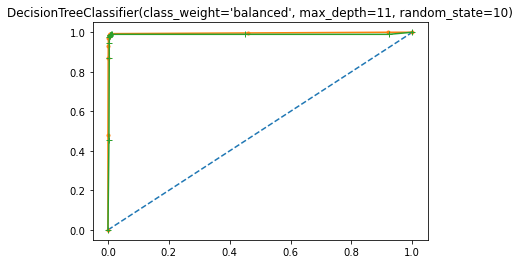

Model Name :  RandomForestClassifier 


Train Score :  0.9934872705743043
Confusion Matrix : Train 
 [[2791   18]
 [   4  565]] 

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      2809
           1       0.97      0.99      0.98       569

    accuracy                           0.99      3378
   macro avg       0.98      0.99      0.99      3378
weighted avg       0.99      0.99      0.99      3378

Test Score :  0.9880106571936057
Confusion Matrix : Test 
 [[1850   23]
 [   4  375]] 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1873
           1       0.94      0.99      0.97       379

    accuracy                           0.99      2252
   macro avg       0.97      0.99      0.98      2252
weighted avg       0.99      0.99      0.99      2252

AUC Train: 0.996
AUC Test: 0.997 



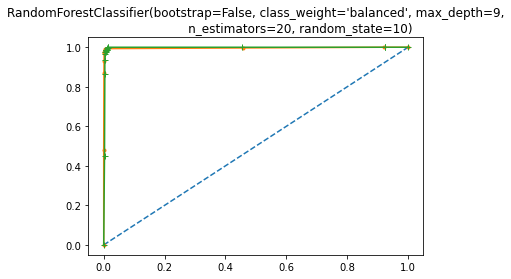

In [60]:
df_result_train=pd.DataFrame()
df_result_test=pd.DataFrame()
for model in models_2p:
    
    print("Model Name : ",str(model).split("(",1)[0],'\n\n')
    model.fit(X_train_2p, y_train_2p)
    y_train_p = model.predict(X_train_2p)
    model_score_train = model.score(X_train_2p, y_train_2p)
    print("Train Score : ",model_score_train)
    print("Confusion Matrix : Train \n",metrics.confusion_matrix(y_train_2p, y_train_p),"\n")
    y_predict = model.predict(X_test_2p)
    model_score = model.score(X_test_2p, y_test_2p)
    print(metrics.classification_report(y_train_2p, y_train_p))
    print("Test Score : ",model_score)
    print("Confusion Matrix : Test \n",metrics.confusion_matrix(y_test_2p, y_predict),"\n")
    print(metrics.classification_report(y_test_2p, y_predict))

    #AUC Calculation
    probs = model.predict_proba(X_train_2p)
    proby = model.predict_proba(X_test_2p)
    # keep probabilities for the positive outcome only
    probs = probs[:, 1]
    proby = proby[:, 1]
    # calculate AUC
    auc_train = roc_auc_score(y_train_2p, probs)
    print('AUC Train: %.3f' % auc_train)
    auc_test = roc_auc_score(y_test_2p, proby)
    print('AUC Test: %.3f' % auc_test,'\n')
    
    # calculate roc curve
    fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train_2p, probs)
    fpr_te, tpr_te, thresholds_te = roc_curve(y_test_2p, proby)
    plt.plot([0, 1], [0, 1], linestyle='--')
    # plot the roc curve for the model
    plt.title(model)
    plt.plot(fpr_tr, tpr_tr, marker='.')
    plt.plot(fpr_te, tpr_te, marker='+')
    # show the plot
    plt.show()
    
    
    temp_train=metrics.classification_report(y_train_2p, y_train_p,output_dict=True)
    temp_test=metrics.classification_report(y_test_2p, y_predict,output_dict=True)
    
    df_result_train = pd.concat([df_result_train,comparison_report(temp_train,auc_train,str(model).split("(",1)[0])])
    #report_test = metrics.classification_report(y_test, y_predict)
    df_result_test = pd.concat([df_result_test,comparison_report(temp_test,auc_test,str(model).split("(",1)[0])])

In [61]:
df_result_train.set_index('Model_Name', inplace=True)


In [62]:
df_result_train

,class,precision,recall,f1_score,support,AUC
Model_Name,,,,,,
LogisticRegression,1,0.955857,0.989455,0.972366,569,0.995812
LinearDiscriminantAnalysis,1,0.962199,0.984183,0.973067,569,0.994398
KNeighborsClassifier,1,0.973822,0.980668,0.977233,569,0.995572
GaussianNB,1,0.933884,0.992970,0.962521,569,0.990710
SVC,1,0.957627,0.992970,0.974978,569,0.995627
DecisionTreeClassifier,1,0.969125,0.992970,0.980903,569,0.996444
RandomForestClassifier,1,0.969125,0.992970,0.980903,569,0.996444


In [63]:
df_result_test.set_index('Model_Name', inplace=True)

In [64]:
df_result_test

,class,precision,recall,f1_score,support,AUC
Model_Name,,,,,,
LogisticRegression,1,0.938119,1.000000,0.968072,379,0.999194
LinearDiscriminantAnalysis,1,0.954198,0.989446,0.971503,379,0.997696
KNeighborsClassifier,1,0.963824,0.984169,0.973890,379,0.997701
GaussianNB,1,0.915459,1.000000,0.955864,379,0.991991
SVC,1,0.942786,1.000000,0.970551,379,0.998170
DecisionTreeClassifier,1,0.942211,0.989446,0.965251,379,0.987018
RandomForestClassifier,1,0.942211,0.989446,0.965251,379,0.997395


In [65]:
df_result_train.drop('class', axis=1).subtract(df_result_test.drop('class', axis=1))

,precision,recall,f1_score,support,AUC
Model_Name,,,,,
LogisticRegression,0.017739,-0.010545,0.004295,190,-0.003382
LinearDiscriminantAnalysis,0.008001,-0.005263,0.001564,190,-0.003298
KNeighborsClassifier,0.009998,-0.003501,0.003343,190,-0.002129
GaussianNB,0.018425,-0.007030,0.006657,190,-0.001281
SVC,0.014841,-0.007030,0.004428,190,-0.002543
DecisionTreeClassifier,0.026914,0.003524,0.015652,190,0.009426
RandomForestClassifier,0.026914,0.003524,0.015652,190,-0.000951


In [101]:
df_test=pd.read_excel('ECom_test.xlsx')

In [102]:
df_test

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50002,1,1,Mobile Phone,3,6,Debit Card,Male,3,4,Mobile,3,Single,7,1,15,0,1,0,120.90
1,50005,1,1,Phone,1,12,CC,Male,2,4,Laptop & Accessory,5,Single,3,0,11,1,1,3,129.60
2,50006,1,1,Computer,1,22,Debit Card,Female,3,5,Mobile Phone,5,Single,8,0,23,0,1,3,134.07
3,50010,1,1,Phone,1,9,E wallet,Male,3,4,Mobile,3,Single,2,0,12,1,1,1,122.93
4,50014,1,11,Mobile Phone,1,6,Debit Card,Male,3,4,Mobile,3,Divorced,1,1,17,0,1,0,133.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,50823,1,15,Mobile Phone,3,11,Debit Card,Male,3,3,Fashion,4,Single,10,1,19,5,7,7,184.46
101,50828,1,1,Computer,3,6,Debit Card,Female,2,3,Mobile,4,Single,2,1,11,1,2,2,123.02
102,50829,1,7,Phone,1,15,Debit Card,Male,2,3,Mobile,5,Divorced,5,0,12,1,1,2,123.62
103,50842,1,20,Mobile Phone,1,13,Credit Card,Female,2,4,Fashion,5,Divorced,8,1,14,4,5,9,200.08


In [103]:
df_test=clean_dataset(df_test)

In [104]:
df_test

,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,1,1,Phone,3,6,Debit Card,Male,3,4,Mobile Phone,3,Single,7,1,15,0,1,0,120.90
1,1,1,Phone,1,12,Credit Card,Male,2,4,Laptop & Accessory,5,Single,3,0,11,1,1,3,129.60
2,1,1,Computer,1,22,Debit Card,Female,3,5,Mobile Phone,5,Single,8,0,23,0,1,3,134.07
3,1,1,Phone,1,9,UPI,Male,3,4,Mobile Phone,3,Single,2,0,12,1,1,1,122.93
4,1,11,Phone,1,6,Debit Card,Male,3,4,Mobile Phone,3,Divorced,1,1,17,0,1,0,133.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,1,15,Phone,3,11,Debit Card,Male,3,3,Fashion,4,Single,10,1,19,5,7,7,184.46
101,1,1,Computer,3,6,Debit Card,Female,2,3,Mobile Phone,4,Single,2,1,11,1,2,2,123.02
102,1,7,Phone,1,15,Debit Card,Male,2,3,Mobile Phone,5,Divorced,5,0,12,1,1,2,123.62
103,1,20,Phone,1,13,Credit Card,Female,2,4,Fashion,5,Divorced,8,1,14,4,5,9,200.08


In [105]:
for col in df_test.select_dtypes(include='object').columns:
    df_test[col] = le.fit_transform(df_test[col])

In [106]:
X_=df_test.drop(['Churn'], axis=1)

In [107]:
y_=df_test['Churn']

In [108]:
#Scale X
X_=RS.transform(X_)

In [109]:
df_predicted_=pd.DataFrame()
for model in models_tuned:
    print("Model Name : ",model,'\n\n')
    df_predicted_[model]=models2[model].predict(X_)
    



Model Name :  LR 


Model Name :  LDA 


Model Name :  KNN 


Model Name :  SVM 


Model Name :  DTC 


Model Name :  RFC 


Model Name :  BAG 


Model Name :  ADA 


Model Name :  GBC 




In [110]:
df_predicted_

,LR,LDA,KNN,SVM,DTC,RFC,BAG,ADA,GBC
0,1,1,1,1,1,1,1,1,1
1,0,0,0,1,1,1,1,1,1
2,1,1,1,1,0,1,1,1,1
3,0,0,1,1,1,1,1,1,1
4,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...
100,0,0,1,0,0,0,0,1,1
101,1,1,1,1,1,1,1,1,1
102,0,0,0,1,0,0,0,1,1
103,0,0,1,0,0,1,0,1,1


In [111]:
for model in models_2p:
    print("Model Name : ",str(model).split("(",1)[0],'\n\n')
    y_out = model.predict(df_predicted_)
    report=metrics.classification_report(y_, y_out,output_dict=True)
    print(report['1']['recall'])
    #print(y_out)


Model Name :  LogisticRegression 


0.925531914893617
Model Name :  LinearDiscriminantAnalysis 


0.9148936170212766
Model Name :  KNeighborsClassifier 


0.925531914893617
Model Name :  GaussianNB 


0.9361702127659575
Model Name :  SVC 


0.925531914893617
Model Name :  DecisionTreeClassifier 


0.8723404255319149
Model Name :  RandomForestClassifier 


0.9148936170212766
